# 1. The negotiation protocol

Examples of:

- how two software agents negotiate a price, round after round;
- that a **strategy** is just a small function: "given the round and the past offers, what do I offer now?";
- what happens when both agents concede at the same speed, and when only one concedes.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from carpool import *

## 1.1 The situation

| | Alice (driver) | Bob (passenger) |
|---|---|---|
| first offer | asks **18 EUR** (`ALICE_START`) | offers **4 EUR** (`BOB_START`) |
| limit | never asks less than **4 EUR** (her detour, `DETOUR`) | never offers more than **18 EUR** (the train, `TRAIN`) |
| gain if the price is $p$ | $p - 4$ | $18 - p$ |

The protocol:

1. at each round $r = 0, 1, \dots, T-1$, **both** agents send an offer at the same time;
2. as soon as Bob offers at least what Alice asks (the offers **cross**), it is a deal: the price is the middle of the two offers;
3. after $T = 10$ rounds (the departure), no deal: Alice drives alone, Bob takes the train, both gain 0.

## 1.2 A strategy is a function

A strategy receives the round `r`, the number of rounds `T`, the list of its own past offers `mine` and the list of the other's past offers `theirs`, and returns the next offer. Here are two **stubborn** agents that never move:

price: None | gains: (0.0, 0.0)


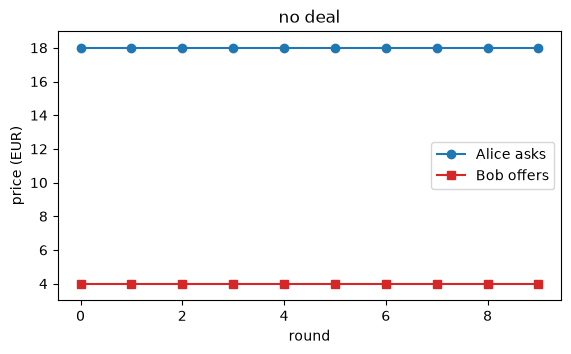

In [5]:
def alice_stubborn(r, T, mine, theirs):
    return 18

def bob_stubborn(r, T, mine, theirs):
    return 4

result = negotiate(alice_stubborn, bob_stubborn)
print("price:", result["price"], "| gains:", result["gains"])
show(result);

Nobody moves: no deal, both gain 0. Someone has to **concede**.

---

**Exercise 1**.  
Write two **linear** strategies: 
  - Alice goes from 18 EUR (round 0) to 4 EUR (last round $T-1$) by equal steps, 
  - Bob from 4 EUR to 18 EUR. 
Run `negotiate` and `show`. At which price and which round do they agree?

In [ ]:
# Exercise 1: your code here
#define alice_linear and bob_linear functions

price: 11.0 at round 5 | gains: (7.0, 7.0)


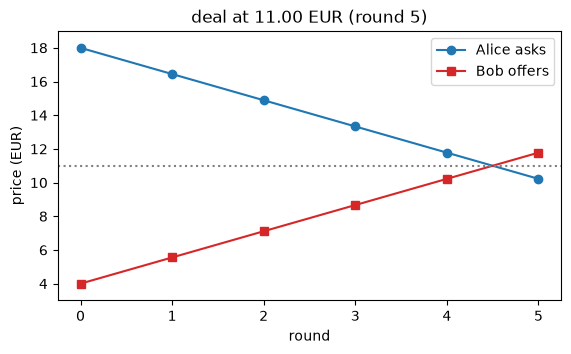

In [ ]:
#then execute this code
result = negotiate(alice_linear, bob_linear)
print("price:", result["price"], "at round", result["round"], "| gains:", result["gains"])
show(result);

**Reading.**   
The offers cross in the middle of the negotiation: price **11 EUR**, each one gains 7 EUR.  
This is the equal split of the surplus, the Nash solution of the cooperative approach.

---

**Exercise 2**.  
Write the negotiation loop **yourself**, without `negotiate`: 
- for $r$ from 0 to 9 ($T=10$), 
  - compute both offers with your linear strategies, 
  - print them, 
  - and stop with the price as soon as they cross (up to 0.5 EUR). 
Do you find the same result?

In [5]:
# Exercise 2: your code here

In [ ]:
alice_offers, bob_offers = [], []
for r in range(T):
#TODO: complete the code to store the offers of Alice and Bob in the lists above

round 0: Alice asks 18.00, Bob offers  4.00
round 1: Alice asks 16.44, Bob offers  5.56
round 2: Alice asks 14.89, Bob offers  7.11
round 3: Alice asks 13.33, Bob offers  8.67
round 4: Alice asks 11.78, Bob offers 10.22
round 5: Alice asks 10.22, Bob offers 11.78
deal at 11.0 EUR


---

**Exercise 3**.  
Now Alice is linear but Bob is stubborn (always 4 EUR).  
What happens? Who gains what?

In [7]:
# Exercise 3: your code here

price: 4.0 at round 9 | gains: (0.0, 14.0)


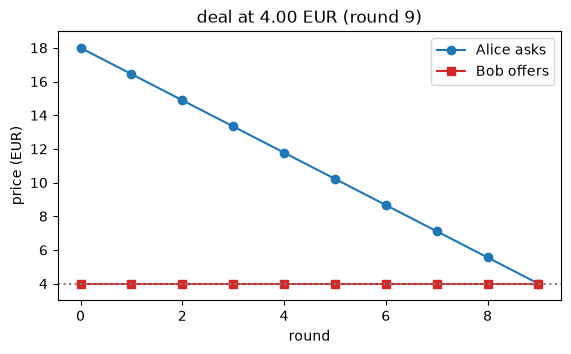

**Reading.**  
Alice concedes alone until her limit: deal at **4 EUR** at the last round, Alice gains nothing, Bob takes the whole surplus.  
An agent that concedes whatever the other does can be **exploited**.  
This is why real strategies watch the time left or the other's behaviour.

---

**Exercise 4**.  
With the two linear agents, compare a short negotiation ($T = 4$) and a long one ($T = 20$): price and round of the deal.

In [9]:
# Exercise 4: your code here

T =  4: price 11.00 EUR at round 2
T = 10: price 11.00 EUR at round 5
T = 20: price 11.00 EUR at round 10


**Reading.**  
The price stays at 11 EUR: both agents are symmetric.  
Only the round of the deal changes (around the middle of the time available).

---

## Key points

| Idea | In the carpool |
|---|---|
| a strategy | a function `(r, T, mine, theirs) -> offer` |
| protocol | simultaneous offers, deal when they cross, deadline $T$ |
| two linear agents | deal at 11 EUR, the equal split |
| conceding alone | exploited: deal at Alice's limit (4 EUR) |